# Deteção de sopros cardíacos em fonocardiogramas (CirCor DigiScope)

Machine Learning II (CC3043), FCUP, 2026/2027. Projeto de grupo.

O objetivo é prever, para cada paciente, se tem um sopro cardíaco (Present), se não tem (Absent) ou se não dá para
saber (Unknown), a partir das gravações de auscultação. Dos três classificadores do enunciado escolhemos dois: uma
CNN 1D sobre o sinal dividido em bandas de frequência e uma GRU bidirecional multitarefa sobre frames log-mel.

O notebook segue a ordem em que pensámos o problema:

1. Regras do problema: o que temos de prever, quanto custa cada erro e que regras saem daí
2. Dados: limpeza e divisão em teste e desenvolvimento
3. Do áudio às entradas das redes: o que vimos no áudio e como preparámos as entradas
4. Modelos: CNN 1D, BiGRU multitarefa e estratégia de treino
5. Treino e validação
6. Avaliação e métricas
7. Consequências práticas: o que os números querem dizer para uma criança rastreada
8. Estado e próximos passos

Estado no checkpoint de 5 de novembro de 2026: a CNN já foi avaliada com cross-validation e a RNN corre do início ao
fim, mas por agora é só um smoke run num fold. Ainda não usámos o conjunto de teste.

### Como correr

1. Python 3.11 e `pip install -r requirements.txt` (as versões são as do ambiente das aulas).
2. O dataset não vem no repositório. Por defeito o código procura-o em
   `../the-circor-digiscope-phonocardiogram-dataset-1.0.3/`. Para usar outra pasta, basta definir a variável de
   ambiente `CIRCOR_DIR`.
3. Correr as células por ordem. Com os interruptores `RETRAIN_*` a `False` (ver a secção 0), o notebook usa os
   resultados guardados em `results/` e corre em poucos minutos.

## 0. Setup

Tal como nas aulas práticas, corremos tudo no CPU (`FORCE_CPU`), porque o tensorflow-metal dá resultados errados em
Apple Silicon. O único código que vem de fora do notebook é a maquinaria de treino, em `src/training.py` (ver a
secção 4.3). As constantes do sinal (frequências, bandas, janelas) estão todas nesta célula e cada uma é explicada na
secção onde é usada.

Os interruptores `RETRAIN_CNN` e `RETRAIN_RNN` decidem se treinamos outra vez ou se usamos os resultados guardados
em `results/`. Mesmo com `False`, se os resultados não existirem o notebook treina na mesma. Treinar a CNN de novo
(5 folds, duas configurações) demora uns 35 min no CPU de um portátil, e o smoke run da RNN demora poucos minutos.

In [1]:
import os, json
from functools import lru_cache
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy import signal
from scipy.io import wavfile
from sklearn.model_selection import StratifiedGroupKFold
import tensorflow as tf
import keras
from keras import layers

FORCE_CPU = True
if FORCE_CPU:
    tf.config.set_visible_devices([], "GPU")

from src.training import run_cv, fold_data, sliding_windows

ROOT = Path.cwd()
DATA_DIR = Path(os.environ.get("CIRCOR_DIR", ROOT.parent / "the-circor-digiscope-phonocardiogram-dataset-1.0.3"))
RECORDINGS_DIR = DATA_DIR / "training_data"
PATIENTS_CSV = DATA_DIR / "training_data.csv"
SPLITS_CSV = ROOT / "splits" / "splits.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "models"
CACHE_DIR = ROOT / "cache"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
CLASSES = ["Present", "Unknown", "Absent"]
PROB_COLS = [f"p_{c}" for c in CLASSES]

SR_RAW = 4000
SR = 2000
BANDS = [(25, 45), (45, 80), (80, 200), (200, 400), (400, 800)]
WIN_SECONDS = 4.0
WIN = int(WIN_SECONDS * SR)
HOP = WIN // 2

MEL_WIN_SECONDS = 0.050
MEL_HOP_SECONDS = 0.020
N_MELS = 32
MEL_FMIN, MEL_FMAX = 25, 800
RNN_WIN = 250
STATES = ["não anotado", "S1", "sístole", "S2", "diástole"]

RETRAIN_CNN = False
RETRAIN_RNN = False

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| dados:", DATA_DIR)

TensorFlow 2.21.0 | Keras 3.15.1 | dados: /Users/ilde/Desktop/fcup/ml2/the-circor-digiscope-phonocardiogram-dataset-1.0.3


## 1. Regras do problema

### 1.1 O que temos de prever

O enunciado pede uma previsão por paciente, com três classes: Present (ouviu-se um sopro), Absent (não se ouviu) e
Unknown (o médico não conseguiu decidir, por exemplo por causa do ruído ou da má qualidade da gravação). Cada paciente
tem normalmente várias gravações, uma por local de auscultação (aórtico, pulmonar, tricúspide e mitral), mas o rótulo
é do paciente e não de cada gravação. Além disso, o sopro pode ouvir-se só em alguns locais, e o dataset diz quais no
campo Murmur locations.

Há ainda uma coisa a ter em conta desde o início. Os dados escondidos da competição podem não trazer os ficheiros de
segmentação (.tsv), por isso os modelos só podem usar o áudio como entrada. Os .tsv podem ajudar no treino, mas nunca
na previsão.

### 1.2 O custo dos erros

Nem todos os erros custam o mesmo. Falhar um sopro, ou um paciente que precisava de ser visto outra vez, é pior do que
um falso alarme. Por isso a métrica do Challenge, a weighted accuracy (WA), conta cada paciente Present 5 vezes, cada
Unknown 3 vezes e cada Absent uma vez:

$$WA = \frac{5\,m_{PP} + 3\,m_{UU} + m_{AA}}{5\,n_P + 3\,n_U + n_A}$$

em que $m_{ij}$ é o número de pacientes previstos como $i$ cuja classe verdadeira é $j$ e $n_j$ é o número de
pacientes da classe $j$. Na matriz de confusão seguimos a convenção do enunciado: as linhas são a classe prevista e as
colunas a verdadeira (o sklearn faz ao contrário). Além da WA, calculamos o recall de cada classe e o macro F1 como
métricas adicionais.

In [2]:
WEIGHTS = (5.0, 3.0, 1.0)


def _to_idx(labels):
    labels = np.asarray(labels)
    if labels.dtype.kind in "iu":
        return labels
    return np.array([CLASSES.index(l) for l in labels])


def confusion_matrix_pua(y_true, y_pred):
    """m[i, j] = número de pacientes previstos como i cuja classe verdadeira é j (ordem Present, Unknown, Absent)."""
    t, p = _to_idx(y_true), _to_idx(y_pred)
    m = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(m, (p, t), 1)
    return m


def weighted_accuracy(y_true, y_pred, weights=WEIGHTS):
    m = confusion_matrix_pua(y_true, y_pred)
    w = np.asarray(weights, dtype=float)
    return float((w * np.diag(m)).sum() / (w * m.sum(axis=0)).sum())


def per_class_recall(y_true, y_pred):
    m = confusion_matrix_pua(y_true, y_pred)
    n_true = m.sum(axis=0)
    return {c: (m[i, i] / n_true[i] if n_true[i] else np.nan) for i, c in enumerate(CLASSES)}


def macro_f1(y_true, y_pred):
    m = confusion_matrix_pua(y_true, y_pred)
    f1 = []
    for i in range(len(CLASSES)):
        tp, n_pred, n_true = m[i, i], m[i, :].sum(), m[:, i].sum()
        prec = tp / n_pred if n_pred else 0.0
        rec = tp / n_true if n_true else 0.0
        f1.append(2 * prec * rec / (prec + rec) if prec + rec else 0.0)
    return float(np.mean(f1))


def report(y_true, y_pred):
    out = {"WA": weighted_accuracy(y_true, y_pred)}
    out.update({f"recall_{c}": r for c, r in per_class_recall(y_true, y_pred).items()})
    out["macro_F1"] = macro_f1(y_true, y_pred)
    return out


def plot_confusion(m, title=None, ax=None):
    ax = ax or plt.gca()
    ax.imshow(m, cmap="Blues")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, int(m[i, j]), ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else "black")
    ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("verdadeiro"); ax.set_ylabel("previsto")
    if title:
        ax.set_title(title)
    return ax

Antes de usarmos a métrica confirmamos que está certa, de três maneiras. Prever Absent para um paciente Present tem de
cair na linha 2 (previsto Absent) e na coluna 0 (verdadeiro Present). Num exemplo pequeno feito à mão, o numerador é
5\*1 + 3\*1 + 1\*2 = 10 e o denominador 5\*2 + 3\*1 + 1\*3 = 16. Por fim, comparamos com a fórmula do enunciado,
escrita tal e qual, em 500 previsões aleatórias.

In [3]:
m = confusion_matrix_pua(["Present"], ["Absent"])
assert m[2, 0] == 1 and m.sum() == 1

y_true = ["Present", "Present", "Unknown", "Absent", "Absent", "Absent"]
y_pred = ["Present", "Absent", "Unknown", "Absent", "Present", "Absent"]
assert np.isclose(weighted_accuracy(y_true, y_pred), 10 / 16)

rng = np.random.default_rng(0)
yt, yp = rng.integers(0, 3, 500), rng.integers(0, 3, 500)
(pp, pu, pa), (up, uu, ua), (ap, au, aa) = confusion_matrix_pua(yt, yp)
expected = (5 * pp + 3 * uu + aa) / (5 * (pp + up + ap) + 3 * (pu + uu + au) + (pa + ua + aa))
assert np.isclose(weighted_accuracy(yt, yp), expected)
print("a métrica bate certo com a fórmula do enunciado")

a métrica bate certo com a fórmula do enunciado


### 1.3 Duas regras de decisão que saem daqui

Os modelos vão dar probabilidades para cada gravação, mas nós temos de dar uma classe por paciente. Há duas regras que
vêm diretamente do problema.

A primeira é sobre como juntar as gravações de um paciente. Se o sopro se ouvir num local, o paciente é Present,
mesmo que nos outros locais não se ouça nada. Por isso, além da média simples, usamos uma agregação em que P(Present)
do paciente é o máximo sobre as gravações, P(Unknown) e P(Absent) são médias, e no fim renormalizamos.

A segunda é sobre como passar das probabilidades para uma classe. O denominador da WA não depende das previsões, por
isso para um paciente com probabilidades $p_c$ o ganho esperado de prever a classe $c$ é $w_c\,p_c$. Se as
probabilidades estiverem calibradas, o melhor é escolher $\arg\max_c w_c p_c$ (a regra de Bayes para esta métrica) em
vez do argmax normal. Na secção 6 vamos ver que esta regra é o que mais pesa no resultado.

In [4]:
def patient_probs(rec_probs, aggregation="mean"):
    """Junta as probabilidades das gravações de cada paciente (rec_probs tem patient_id e as colunas p_<classe>).
    Com "mean" fazemos só a média. Com "max_present" usamos o máximo para P(Present), a média para as outras duas,
    e no fim renormalizamos."""
    g = rec_probs.groupby("patient_id")
    p = g[PROB_COLS].mean()
    if aggregation == "mean":
        pass
    elif aggregation == "max_present":
        p["p_Present"] = g["p_Present"].max()
        p = p.div(p.sum(axis=1), axis=0)
    else:
        raise ValueError(aggregation)
    return p


def decide_argmax(probs):
    return np.array(CLASSES)[np.argmax(np.asarray(probs), axis=1)]


def decide_bayes(probs, weights=WEIGHTS):
    return np.array(CLASSES)[np.argmax(np.asarray(probs) * np.asarray(weights), axis=1)]


DECISIONS = {"argmax": decide_argmax, "bayes": decide_bayes}


def predict_patients(rec_probs, aggregation, decision):
    """Agrega por paciente e aplica a regra de decisão. Devolve as probabilidades e a coluna pred, por patient_id."""
    p = patient_probs(rec_probs, aggregation)
    p["pred"] = DECISIONS[decision](p[PROB_COLS].to_numpy())
    return p

Um exemplo pequeno. O paciente 1 tem uma gravação com um sopro claro e outra sem nada: com a média fica com
P(Present) = 0.5, com o máximo fica com mais. O paciente 2 mostra a diferença entre as duas regras de decisão. Pelo
argmax é Absent (0.7 contra 0.2), mas com os pesos 5\*0.2 = 1.0 é mais do que 1\*0.7, por isso a regra de Bayes diz
Present.

In [5]:
rec = pd.DataFrame({"patient_id": [1, 1, 2], "p_Present": [0.9, 0.1, 0.2],
                    "p_Unknown": [0.05, 0.1, 0.1], "p_Absent": [0.05, 0.8, 0.7]})
mean, mx = patient_probs(rec, "mean"), patient_probs(rec, "max_present")
assert np.isclose(mean.loc[1, "p_Present"], 0.5)
assert mx.loc[1, "p_Present"] > mean.loc[1, "p_Present"] and np.allclose(mx.sum(axis=1), 1.0)
assert decide_argmax(mean.loc[[2]].to_numpy())[0] == "Absent"
assert decide_bayes(mean.loc[[2]].to_numpy())[0] == "Present"
pd.concat({"média": mean, "máximo para Present": mx}, axis=1).round(3)

média                    máximo para Present                   
           p_Present p_Unknown p_Absent           p_Present p_Unknown p_Absent
patient_id                                                                    
1                0.5     0.075    0.425               0.643     0.054    0.304
2                0.2     0.100    0.700               0.200     0.100    0.700

### 1.4 Regras do protocolo

O enunciado impõe mais três regras, que condicionam a forma como dividimos os dados. A divisão é feita por paciente,
e todas as gravações de um paciente ficam no mesmo subconjunto. O conjunto de teste não pode ser usado para nenhuma
decisão (arquitetura, hiperparâmetros, pré-processamento, early stopping ou limiares). E convém estratificar, para
todos os subconjuntos terem proporções de classes parecidas.

Por isso guardamos 20% dos pacientes como conjunto de teste, fechado até ao fim, e fazemos todas as escolhas com
cross-validation de 5 folds nos restantes. Na secção 2.2 vamos ver que dividir por paciente não chega, porque há
crianças que aparecem com dois IDs.

## 2. Dados: limpeza e divisão

### 2.1 Tabela de pacientes

O training_data.csv tem uma linha por paciente. Mudamos os nomes das colunas que vamos usar para nomes mais curtos e
vemos como estão distribuídas as classes.

In [6]:
def load_patients():
    df = pd.read_csv(PATIENTS_CSV, dtype={"Patient ID": int})
    df = df.rename(columns={"Patient ID": "patient_id", "Recording locations:": "recording_locations",
                            "Murmur": "murmur", "Murmur locations": "murmur_locations",
                            "Campaign": "campaign", "Additional ID": "additional_id", "Age": "age"})
    df["additional_id"] = pd.to_numeric(df["additional_id"], errors="coerce").astype("Int64")
    return df


patients = load_patients()
print(f"{len(patients)} pacientes")
counts = patients["murmur"].value_counts()[CLASSES]
display(pd.DataFrame({"pacientes": counts, "%": (100 * counts / counts.sum()).round(1)}))

y = patients["murmur"]
for c in CLASSES:
    print(f"prever sempre {c:<8}: accuracy {np.mean(y == c):.3f} | weighted accuracy {weighted_accuracy(y, [c] * len(y)):.3f}")
assert np.isclose(weighted_accuracy(y, ["Absent"] * len(y)), 695 / 1794)
assert np.isclose(weighted_accuracy(y, ["Present"] * len(y)), 895 / 1794)

942 pacientes


,pacientes,%
murmur,,
Present,179,19.0
Unknown,68,7.2
Absent,695,73.8


prever sempre Present : accuracy 0.190 | weighted accuracy 0.499
prever sempre Unknown : accuracy 0.072 | weighted accuracy 0.114
prever sempre Absent  : accuracy 0.738 | weighted accuracy 0.387


Prever sempre Absent dá a melhor accuracy, mas em WA quem ganha é prever sempre Present (o denominador é
5\*179 + 3\*68 + 695 = 1794). Ou seja, com esta métrica um modelo só serve para alguma coisa se tiver um WA acima do
de prever sempre Present.

Os dados vêm de duas campanhas de rastreio, CC2014 e CC2015. Vemos também a idade:

In [7]:
display(pd.crosstab(patients["campaign"], patients["murmur"], normalize="index").round(3)[CLASSES])
pd.crosstab(patients["age"].fillna("em falta"), patients["murmur"])[CLASSES]

murmur,Present,Unknown,Absent
campaign,,,
CC2014,0.164,0.052,0.784
CC2015,0.208,0.086,0.706


murmur,Present,Unknown,Absent
age,,,
Adolescent,16,3,53
Child,132,37,495
Infant,25,25,76
Neonate,1,1,4
em falta,5,2,67


As duas campanhas têm proporções de classes diferentes e podem ter sido gravadas em condições diferentes, por isso
na divisão (secção 2.3) estratificamos por sopro x campanha. Também se vê que os bebés (Infant) têm muito mais
Unknown do que as crianças mais velhas, o que faz sentido, porque choram e mexem-se durante a auscultação. É uma
primeira pista de que o Unknown tem a ver com a qualidade da gravação.

### 2.2 A mesma criança com dois IDs

Alguns pacientes têm um Additional ID que aponta para outro Patient ID. Fomos ver o que isso quer dizer. Para juntar
os IDs que se referem à mesma criança usamos um union-find, e cada grupo fica com um group_id.

In [8]:
def link_groups(patient_ids, additional_ids):
    """Union-find simples: junta cada Patient ID com o Additional ID para onde aponta e devolve
    {patient_id: group_id}, em que o group_id é o menor ID do grupo."""
    parent = {p: p for p in patient_ids}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for p, a in zip(patient_ids, additional_ids):
        if a in parent:
            ra, rp = find(a), find(p)
            if ra != rp:
                parent[max(ra, rp)] = min(ra, rp)
    return {p: find(p) for p in patient_ids}


patients["group_id"] = patients["patient_id"].map(link_groups(
    patients["patient_id"].tolist(), [int(a) if pd.notna(a) else None for a in patients["additional_id"]]))

linked = patients.dropna(subset=["additional_id"])
gid = dict(zip(patients["patient_id"], patients["group_id"]))
assert all(gid[a] == gid[b] for a, b in zip(linked["patient_id"], linked["additional_id"]))
print(f"pacientes com Additional ID: {len(linked)}; todos apontam para outro paciente público: "
      f"{linked['additional_id'].isin(patients['patient_id']).all()}")
print(f"grupos depois de ligar os IDs: {patients['group_id'].nunique()} (eram {len(patients)} Patient ID)")

lab = patients.set_index("patient_id")["murmur"]
camp = patients.set_index("patient_id")["campaign"]
pairs = linked[linked["patient_id"] < linked["additional_id"]]
display(pd.crosstab(linked["campaign"].rename("campanha do paciente"),
                    linked["additional_id"].map(camp).rename("campanha do ID ligado")))
display(pd.crosstab(pairs["murmur"].rename("visita A"), pairs["additional_id"].map(lab).rename("visita B")))
print("pares com rótulos diferentes:", int((pairs["murmur"] != pairs["additional_id"].map(lab)).sum()), "de", len(pairs))

pacientes com Additional ID: 140; todos apontam para outro paciente público: True
grupos depois de ligar os IDs: 872 (eram 942 Patient ID)


campanha do ID ligado,CC2014,CC2015
campanha do paciente,,
CC2014,0,70
CC2015,70,0


visita B,Absent,Present,Unknown
visita A,,,
Absent,36,3,4
Present,1,18,3
Unknown,2,2,1


pares com rótulos diferentes: 15 de 70


Há 70 crianças que foram gravadas nas duas campanhas, uma vez em cada, e que por isso aparecem com dois Patient ID.
Se dividíssemos os dados só pelo Patient ID, a mesma criança podia ficar no treino e no teste, e os resultados iam
parecer melhores do que são. Por isso a divisão é feita pelo group_id e não pelo Patient ID. Em 15 destes pares as
duas visitas têm rótulos diferentes, portanto parte do ruído nos rótulos é real (outra visita, outra qualidade de
gravação).

### 2.3 Divisão em teste e desenvolvimento

Para cumprir as regras da secção 1.4 usamos duas vezes o StratifiedGroupKFold do scikit-learn, com a mesma seed.
Primeiro dividimos os 942 pacientes em 5 folds e o primeiro (20%) passa a ser o conjunto de teste. Depois dividimos
os restantes, o conjunto de desenvolvimento, em 5 folds de CV. Os grupos são o group_id e os estratos são
sopro x campanha.

A divisão está guardada em splits/splits.csv. O notebook volta a calculá-la e confirma que dá exatamente o mesmo, o
que também apanha uma eventual mudança de comportamento numa versão nova do sklearn. Se o ficheiro não existir, é
criado aqui.

In [9]:
N_FOLDS = 5


def make_splits(patients, n_folds=N_FOLDS, seed=SEED):
    """Primeiro tiramos 20% dos pacientes para teste (é um dos 5 folds de um StratifiedGroupKFold) e depois
    dividimos o resto em folds de CV, sempre agrupado por group_id e estratificado por sopro x campanha."""
    strata = (patients["murmur"] + "_" + patients["campaign"]).to_numpy()
    groups = patients["group_id"].to_numpy()

    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    dev_idx, test_idx = next(outer.split(np.zeros(len(patients)), strata, groups))

    out = patients[["patient_id", "group_id", "murmur", "campaign"]].copy()
    out["split"] = "dev"
    out.loc[out.index[test_idx], "split"] = "test"
    out["fold"] = -1

    inner = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for k, (_, val_idx) in enumerate(inner.split(np.zeros(len(dev_idx)), strata[dev_idx], groups[dev_idx])):
        out.loc[out.index[dev_idx[val_idx]], "fold"] = k
    check_splits(out)
    return out


def check_splits(splits):
    """Confirma que cada grupo fica todo no mesmo sítio: no teste ou num único fold."""
    where = splits["split"] + splits["fold"].astype(str)
    n_places = where.groupby(splits["group_id"]).nunique()
    assert (n_places == 1).all(), f"grupos partidos entre subconjuntos: {n_places[n_places > 1].index.tolist()}"
    assert (splits.loc[splits["split"] == "dev", "fold"] >= 0).all()


def proportions(splits):
    key = splits["split"].where(splits["split"] == "test", "fold " + splits["fold"].astype(str))
    tab = pd.crosstab(key, splits["murmur"])[CLASSES]
    tab["n"] = tab.sum(axis=1)
    for c in CLASSES:
        tab[f"%{c}"] = (100 * tab[c] / tab["n"]).round(1)
    return tab


splits = make_splits(patients)
assert splits.equals(make_splits(patients))
assert 0.17 < (splits["split"] == "test").mean() < 0.23
if SPLITS_CSV.exists():
    assert splits.equals(pd.read_csv(SPLITS_CSV)), "a divisão calculada não é igual à guardada"
else:
    SPLITS_CSV.parent.mkdir(exist_ok=True)
    splits.to_csv(SPLITS_CSV, index=False)

test_ids = set(splits.loc[splits["split"] == "test", "patient_id"])
dev_ids = set(splits.loc[splits["split"] == "dev", "patient_id"])
labels = splits.set_index("patient_id")["murmur"]
proportions(splits)

murmur,Present,Unknown,Absent,n,%Present,%Unknown,%Absent
split,,,,,,,
fold 0,29,11,111,151,19.2,7.3,73.5
fold 1,28,11,112,151,18.5,7.3,74.2
fold 2,29,11,111,151,19.2,7.3,73.5
fold 3,28,11,111,150,18.7,7.3,74.0
fold 4,29,10,111,150,19.3,6.7,74.0
test,36,14,139,189,19.0,7.4,73.5


In [10]:
key = splits["split"].where(splits["split"] == "test", "dev")
display(pd.crosstab(key, splits["campaign"], normalize="index").round(3))
linked_groups = splits[splits["group_id"].duplicated(keep=False)]
print(f"pacientes ligados: {len(linked_groups)} em {linked_groups['group_id'].nunique()} grupos; "
      f"{(linked_groups['split'] == 'test').sum()} estão no teste (sempre junto com o seu par)")

campaign,CC2014,CC2015
split,,
dev,0.409,0.591
test,0.407,0.593


pacientes ligados: 140 em 70 grupos; 28 estão no teste (sempre junto com o seu par)


Os cinco folds e o teste ficam com proporções de classes e de campanhas quase iguais, e os pares de IDs ligados
nunca ficam separados.

### 2.4 Gravações e rótulos por local

Cada paciente tem um ficheiro <id>.txt com a lista das suas gravações (local, .hea, .wav e .tsv). Antes de as ler
falta decidir o rótulo de cada gravação. Como vimos na secção 1.1, num paciente Present o sopro pode não se ouvir em
todos os locais. Se cada gravação herdasse o rótulo do paciente, estaríamos a ensinar à rede que algumas gravações
sem sopro são Present. Por isso as gravações de um paciente Present só ficam Present nos locais que aparecem em
Murmur locations, e nos outros ficam Absent. Nos pacientes Unknown e Absent, as gravações herdam o rótulo.

In [11]:
def recording_label(patient_murmur, murmur_locations, location):
    if patient_murmur != "Present":
        return patient_murmur
    heard = set(str(murmur_locations).split("+"))
    return "Present" if location in heard else "Absent"


assert recording_label("Present", "AV+TV", "TV") == "Present"
assert recording_label("Present", "AV+TV", "MV") == "Absent"
assert recording_label("Unknown", np.nan, "MV") == "Unknown"
assert recording_label("Absent", np.nan, "AV") == "Absent"


def load_recordings(patients):
    """Uma linha por ficheiro .wav, a partir do <id>.txt de cada paciente. A duração vem do .hea (número de amostras)."""
    rows = []
    for p in patients.itertuples(index=False):
        lines = (RECORDINGS_DIR / f"{p.patient_id}.txt").read_text().splitlines()
        n_rec = int(lines[0].split()[1])
        for line in lines[1:1 + n_rec]:
            location, hea, wav, tsv = line.split()
            n_samples = int((RECORDINGS_DIR / hea).read_text().split()[3])
            rows.append(dict(
                patient_id=p.patient_id, group_id=p.group_id, recording=wav[:-4], location=location,
                wav=str(RECORDINGS_DIR / wav), tsv=str(RECORDINGS_DIR / tsv),
                duration=n_samples / SR_RAW, patient_label=p.murmur,
                rec_label=recording_label(p.murmur, p.murmur_locations, location),
                campaign=p.campaign))
    return pd.DataFrame(rows)


recs = load_recordings(patients)
print(f"{len(recs)} gravações")

3163 gravações


A partir daqui só usamos o conjunto de desenvolvimento. Até a exploração do áudio, que serve para decidir o
pré-processamento, é feita só nestes pacientes.

In [12]:
dev_patients = patients[patients["patient_id"].isin(dev_ids)].reset_index(drop=True)
dev_recs = recs[recs["patient_id"].isin(dev_ids)].reset_index(drop=True)
assert not set(dev_recs["patient_id"]) & test_ids
print(f"conjunto de desenvolvimento: {len(dev_patients)} pacientes, {len(dev_recs)} gravações")

conjunto de desenvolvimento: 753 pacientes, 2549 gravações


Quantas gravações há por paciente, de que locais, e quanto duram:

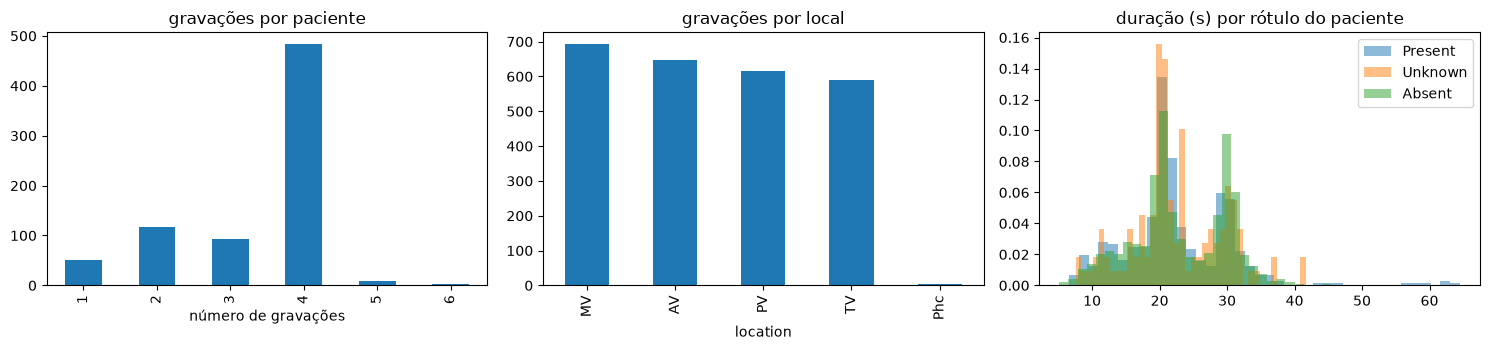

,count,mean,std,min,25%,50%,75%,max
patient_label,,,,,,,,
Absent,1924.0,23.0,7.1,5.2,19.1,21.6,29.6,58.8
Present,497.0,22.5,8.0,6.6,19.2,21.2,28.7,64.5
Unknown,128.0,22.5,6.7,7.6,19.3,21.1,28.0,41.7


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
dev_recs.groupby("patient_id").size().value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("gravações por paciente"); axes[0].set_xlabel("número de gravações")
dev_recs["location"].value_counts().plot.bar(ax=axes[1]); axes[1].set_title("gravações por local")
for c in CLASSES:
    axes[2].hist(dev_recs.loc[dev_recs["patient_label"] == c, "duration"], bins=40, alpha=0.5, density=True, label=c)
axes[2].set_title("duração (s) por rótulo do paciente"); axes[2].legend()
plt.tight_layout(); plt.show()
dev_recs.groupby("patient_label")["duration"].describe().round(1)

As durações são parecidas nas três classes, por isso a duração não serve de atalho ao modelo. Todas as gravações têm
mais de 5 s, o que quer dizer que dá sempre para tirar uma janela de 4 s sem padding.

Fomos também confirmar se a regra dos rótulos por local fazia mesmo falta, ou seja, em quantos pacientes Present o
sopro não se ouve em todos os locais:

In [14]:
present = dev_patients[dev_patients["murmur"] == "Present"]
n_heard = present["murmur_locations"].str.split("+").str.len()
n_recorded = present["recording_locations"].str.split("+").str.len()
partial = (present["murmur_locations"].str.split("+").apply(set)
           != present["recording_locations"].str.split("+").apply(set))
print(f"pacientes Present em que o sopro não se ouve em todos os locais gravados: {partial.sum()} / {len(present)}")
display(pd.crosstab(n_heard.rename("locais onde se ouve"), n_recorded.rename("locais gravados")))
pd.crosstab(dev_recs["patient_label"], dev_recs["rec_label"], margins=True)

pacientes Present em que o sopro não se ouve em todos os locais gravados: 54 / 143


locais gravados,1,2,3,4,5,6
locais onde se ouve,,,,,,
1,8,6,2,9,0,0
2,0,14,5,18,1,0
3,0,0,8,12,0,1
4,0,0,0,58,0,0
5,0,0,0,0,1,0


rec_label,Absent,Present,Unknown,All
patient_label,,,,
Absent,1924,0,0,1924
Present,93,404,0,497
Unknown,0,0,128,128
All,2017,404,128,2549


Em muitos pacientes Present o sopro não se ouve em todos os locais, por isso a regra faz falta. A segunda tabela
mostra o efeito: as gravações de pacientes Present feitas onde o sopro não se ouviu passam a Absent.

Vimos também como são os sopros:

In [15]:
for col in ["Systolic murmur timing", "Diastolic murmur timing", "Systolic murmur pitch", "Systolic murmur grading"]:
    print(col, present[col].fillna("nenhum").value_counts().to_dict())

Systolic murmur timing {'Holosystolic': 84, 'Early-systolic': 44, 'Mid-systolic': 14, 'nenhum': 1}
Diastolic murmur timing {'nenhum': 138, 'Early-diastolic': 5}
Systolic murmur pitch {'Low': 68, 'Medium': 39, 'High': 35, 'nenhum': 1}
Systolic murmur grading {'I/VI': 82, 'III/VI': 39, 'II/VI': 21, 'nenhum': 1}


Quase todos os sopros são sistólicos, por isso saber onde está a sístole no sinal deve ajudar. Muitos têm tom médio
ou alto, o que quer dizer que a entrada tem de manter as frequências bem acima dos 200 Hz. O grau mais comum é o
I/VI, que é o mais fraco.

## 3. Do áudio às entradas das redes

Nesta secção olhamos para o áudio do conjunto de desenvolvimento e, a partir do que vemos, decidimos como preparar as
entradas da CNN e da RNN.

### 3.1 Ficheiros de segmentação (.tsv)

Cada .tsv tem intervalos com um estado: 1 = S1, 2 = sístole, 3 = S2, 4 = diástole e 0 = não anotado. Medimos que
fração de cada gravação ficou por anotar e quanto dura o ciclo cardíaco.

,count,mean,std,min,25%,50%,75%,max
patient_label,,,,,,,,
Absent,1924.0,0.45,0.29,-0.0,0.17,0.48,0.70,1.00
Present,497.0,0.41,0.30,0.0,0.11,0.40,0.68,0.96
Unknown,128.0,0.69,0.21,0.0,0.59,0.75,0.84,0.93


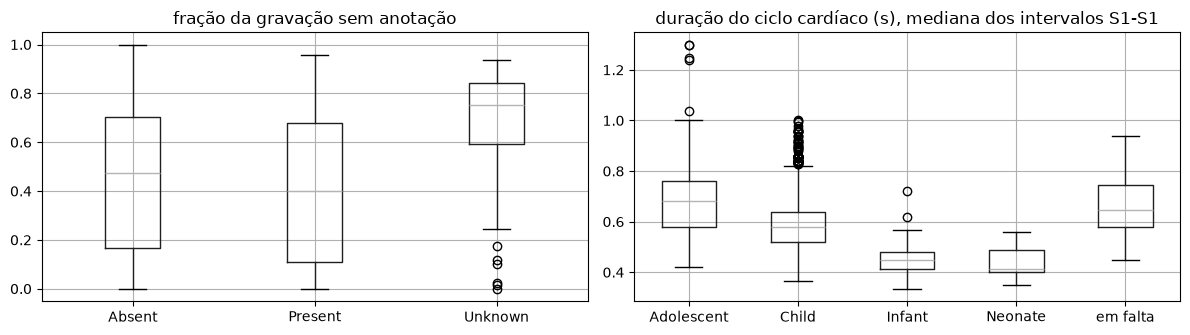

duração do ciclo em todas as gravações de desenvolvimento: mediana 0.58 s, percentil 95 0.81 s


In [16]:
def read_tsv(path):
    return np.loadtxt(path, ndmin=2)


def unannotated_fraction(tsv_path, duration):
    """Fração da gravação que os anotadores não conseguiram segmentar."""
    seg = read_tsv(tsv_path)
    annotated = sum(end - start for start, end, state in seg if state != 0)
    return 1.0 - annotated / duration


def cycle_length(tsv):
    """Duração do ciclo numa gravação: a mediana dos intervalos entre S1 seguidos, sem os que saem de 0.2-2 s."""
    seg = read_tsv(tsv)
    s1 = seg[seg[:, 2] == 1, 0]
    d = np.diff(s1)
    return np.median(d[(d > 0.2) & (d < 2.0)]) if len(d) else np.nan


dev_recs["unannotated"] = [unannotated_fraction(t, d) for t, d in zip(dev_recs["tsv"], dev_recs["duration"])]
dev_recs["cycle_s"] = [cycle_length(t) for t in dev_recs["tsv"]]
display(dev_recs.groupby("patient_label")["unannotated"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
dev_recs.boxplot(column="unannotated", by="patient_label", ax=axes[0])
axes[0].set_title("fração da gravação sem anotação"); axes[0].set_xlabel("")
age = dev_recs["patient_id"].map(patients.set_index("patient_id")["age"]).fillna("em falta")
dev_recs.assign(age=age).boxplot(column="cycle_s", by="age", ax=axes[1])
axes[1].set_title("duração do ciclo cardíaco (s), mediana dos intervalos S1-S1"); axes[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()
print("duração do ciclo em todas as gravações de desenvolvimento: mediana %.2f s, percentil 95 %.2f s"
      % (dev_recs["cycle_s"].median(), dev_recs["cycle_s"].quantile(0.95)))

A maior parte de cada gravação Unknown não foi segmentada pelos anotadores: a fração sem anotação é muito maior do
que nas Absent e nas Present. Isto sugere que o Unknown é sobretudo uma questão de qualidade do sinal, e que o
estado 0 dos .tsv funciona como um indicador dessa qualidade frame a frame. Foi daqui que veio a ideia da saída extra
da RNN, que aprende a prever o estado de cada frame, incluindo o 0. Como vimos na secção 1.1, os .tsv só podem servir
de alvo no treino, nunca de entrada.

Quase todos os ciclos cardíacos duram menos de 1 s. Uma janela de 4 s apanha então vários batimentos, e um receptive
field de ~1 s na CNN chega para cobrir um ciclo inteiro.

### 3.2 Olhar para os sinais

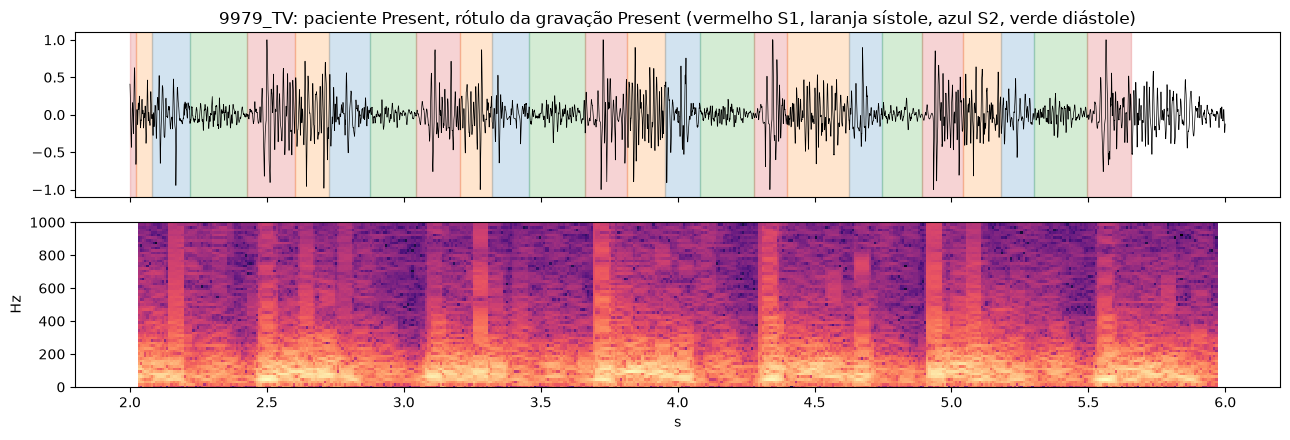

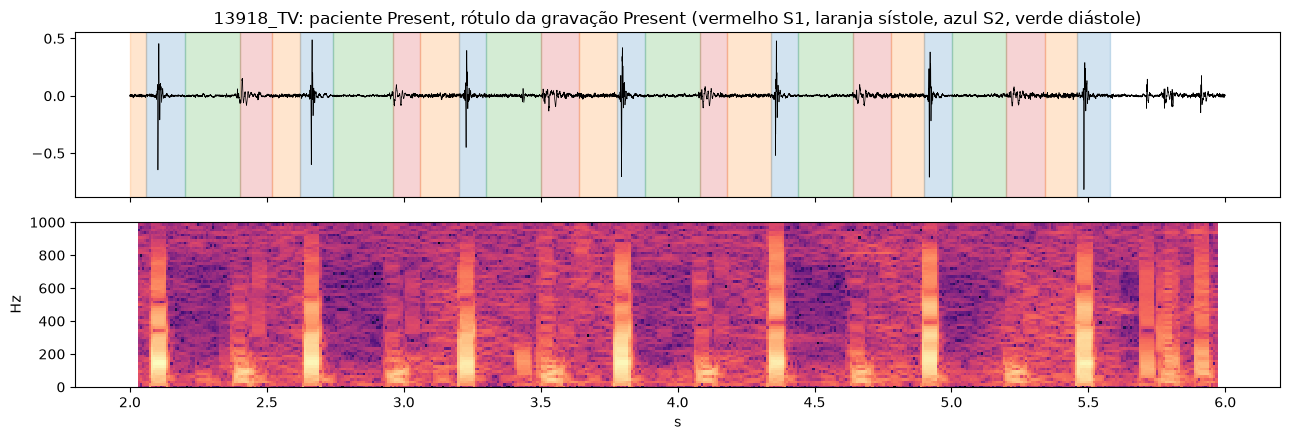

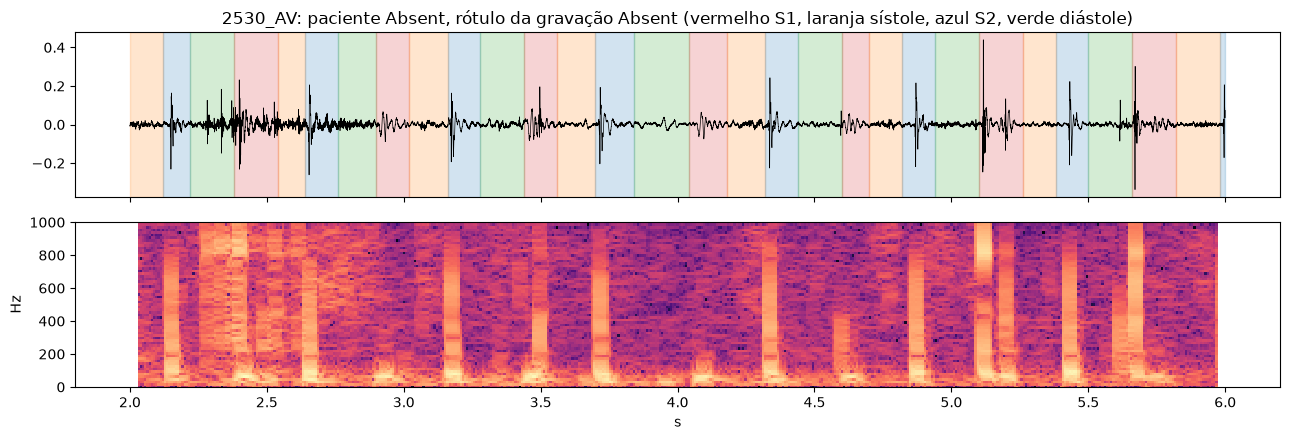

In [17]:
STATE_COLORS = {1: "tab:red", 2: "tab:orange", 3: "tab:blue", 4: "tab:green"}


def load_wav(path):
    sr, x = wavfile.read(path)
    assert sr == SR_RAW, f"{path}: taxa de amostragem inesperada ({sr})"
    return x.astype(np.float32) / 32768.0


def show_recording(name, t0=2.0, t1=6.0):
    """Mostra um bocado da gravação com as fases do .tsv pintadas por cima e o espectrograma por baixo."""
    r = dev_recs.set_index("recording").loc[name]
    x = load_wav(r["wav"])
    t = np.arange(len(x)) / SR_RAW
    sel = (t >= t0) & (t < t1)
    fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
    axes[0].plot(t[sel], x[sel], lw=0.5, color="black")
    for start, end, s in read_tsv(r["tsv"]):
        if s in STATE_COLORS and end > t0 and start < t1:
            axes[0].axvspan(max(start, t0), min(end, t1), color=STATE_COLORS[int(s)], alpha=0.2)
    axes[0].set_title(f"{name}: paciente {r['patient_label']}, rótulo da gravação {r['rec_label']} "
                      "(vermelho S1, laranja sístole, azul S2, verde diástole)")
    f, tt, S = signal.spectrogram(x[sel], fs=SR_RAW, nperseg=256, noverlap=224)
    axes[1].pcolormesh(tt + t0, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1].set_ylim(0, 1000); axes[1].set_ylabel("Hz"); axes[1].set_xlabel("s")
    plt.tight_layout(); plt.show()


show_recording("9979_TV")
show_recording("13918_TV")
show_recording("2530_AV")

Na 9979_TV (sopro holossistólico de grau III/VI) todos os intervalos S1 + sístole, a vermelho e laranja, estão cheios
de energia em banda larga. Na 13918_TV (grau I/VI, só se ouve no TV) quase não se vê o sopro a olho, e há muitos
sopros assim fracos no dataset. Na 2530_AV, de um paciente Absent, a sístole entre os sons cardíacos é silenciosa.

### 3.3 Espectro: gravação inteira vs só a sístole

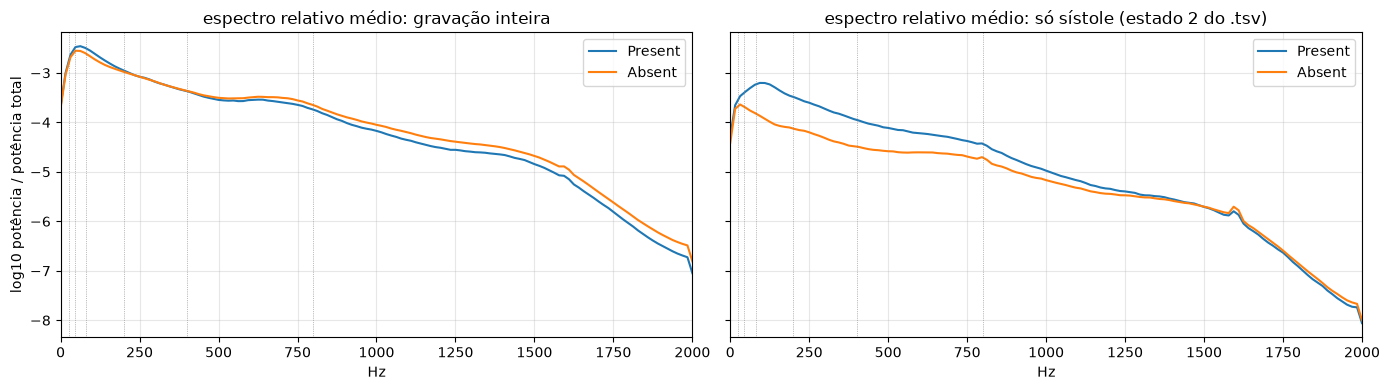

Present menos Absent, em log10 da potência (+0.30 = o dobro da potência):


,gravação inteira,só sístole
banda (Hz),,
25-100,0.09,0.43
100-200,0.08,0.71
200-400,0.00,0.59
400-800,-0.06,0.40
800-2000,-0.17,0.05


In [18]:
BAND_EDGES = [(25, 100), (100, 200), (200, 400), (400, 800), (800, 2000)]


def spectra_by_label(systole_only):
    """Espectro médio (Welch) das gravações Present e Absent, dividido pela potência total de cada gravação para as
    gravações mais fortes não pesarem mais. Com systole_only=True só usamos os troços de sístole do .tsv."""
    out = {c: [] for c in ["Present", "Absent"]}
    for wav, tsv, lab_ in zip(dev_recs["wav"], dev_recs["tsv"], dev_recs["rec_label"]):
        if lab_ == "Unknown":
            continue
        x = load_wav(wav)
        if systole_only:
            parts = [x[int(s * SR_RAW):int(e * SR_RAW)] for s, e, st in read_tsv(tsv) if st == 2]
            parts = [q - q.mean() for q in parts if len(q) > 64]
            if not parts:
                continue
            p = np.mean([signal.welch(q, fs=SR_RAW, nperseg=min(256, len(q)), nfft=256)[1] for q in parts], axis=0)
        else:
            _, p = signal.welch(x, fs=SR_RAW, nperseg=256, nfft=256)
        out[lab_].append(np.log10(p / np.mean(x ** 2) + 1e-12))
    return {c: np.mean(v, axis=0) for c, v in out.items()}


freqs = np.fft.rfftfreq(256, 1 / SR_RAW)
whole, systole = spectra_by_label(False), spectra_by_label(True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (title, sp) in zip(axes, [("gravação inteira", whole), ("só sístole (estado 2 do .tsv)", systole)]):
    for c in sp:
        ax.plot(freqs, sp[c], label=c)
    for lo, hi in BANDS:
        ax.axvline(lo, color="gray", lw=0.5, ls=":")
    ax.axvline(BANDS[-1][1], color="gray", lw=0.5, ls=":")
    ax.set_xlim(0, 2000); ax.set_xlabel("Hz"); ax.set_title(f"espectro relativo médio: {title}")
    ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("log10 potência / potência total")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_spectra.png", dpi=120); plt.show()

rows = []
for lo, hi in BAND_EDGES:
    band = (freqs >= lo) & (freqs < hi)
    rows.append({"banda (Hz)": f"{lo}-{hi}",
                 "gravação inteira": np.mean(whole["Present"][band] - whole["Absent"][band]),
                 "só sístole": np.mean(systole["Present"][band] - systole["Absent"][band])})
print("Present menos Absent, em log10 da potência (+0.30 = o dobro da potência):")
pd.DataFrame(rows).set_index("banda (Hz)").round(2)

Na gravação inteira as duas classes quase não se distinguem: o S1 e o S2 dominam o espectro e um sopro fraco
perde-se na média. Dentro da sístole já é diferente. As gravações Present têm várias vezes mais potência em todas as
bandas entre 25 e 800 Hz, e praticamente a mesma acima dos 800 Hz. As linhas a tracejado são as bandas que acabámos
por usar na CNN (secção 3.5).

Por isso decidimos baixar a amostragem para 2 kHz (Nyquist de 1 kHz) e usar um banco de filtros entre 25 e 800 Hz na
CNN, e um log-mel limitado a 25-800 Hz na RNN. O facto de o sopro só aparecer quando se olha fase a fase também é o
argumento para a saída de segmentação da RNN.

### 3.4 Resumo: das observações às decisões

| Observação | Decisão |
|---|---|
| Prever sempre Present já ganha a prever sempre Absent em WA | Prever sempre Present é a referência para todos os resultados |
| 70 crianças aparecem com dois Patient ID | Divisão agrupada por criança (group_id) |
| As proporções das classes mudam com a campanha | Divisão estratificada por sopro x campanha |
| Muitas vezes o sopro só se ouve em alguns locais | Rótulos por gravação conforme o local; máximo de P(Present) sobre os locais |
| Os sopros são quase sempre sistólicos e só se destacam fase a fase | Modelar a fase do ciclo (saída de segmentação na RNN) |
| A maioria das gravações Unknown não se consegue segmentar | Estado 0 das frames como alvo auxiliar (um sinal de qualidade) |
| A diferença na sístole vai de 25 a 800 Hz e o ciclo dura menos de 1 s | 2 kHz, 5 bandas entre 25 e 800 Hz, janelas de 4 s, receptive field de ~1 s |
| Muitos sopros são de grau I/VI (fracos) | Contar com confusões entre Present e Absent; a accuracy simples não diz muito |

### 3.5 Entrada da CNN: sinal dividido em bandas

Primeiro passamos o sinal de 4 kHz para 2 kHz com o `resample_poly`, que já aplica o filtro anti-aliasing. Depois
aplicamos um banco de filtros Butterworth passa-banda de ordem 4 (25-45, 45-80, 80-200, 200-400 e 400-800 Hz) com o
`sosfiltfilt`, que tem fase zero e por isso mantém o S1 e o S2 alinhados entre canais. As quatro primeiras bandas
são as de Potes et al., que ganharam o PhysioNet Challenge 2016. Acrescentámos a de 400-800 Hz por causa dos sopros
de tom médio e alto.

Para normalizar usamos um z-score robusto por canal (mediana e MAD). Os sons cardíacos vêm aos picos e a fricção do
estetoscópio cria picos enormes, por isso um z-score normal (média e desvio padrão) ia depender de quantos picos cada
gravação tem. Os valores acima de 20 em módulo são cortados.

No treino tiramos um crop aleatório de 4 s de cada gravação em cada época. Na inferência usamos janelas de 4 s com
50% de sobreposição e fazemos a média das probabilidades por gravação. Como o pré-processamento é sempre igual,
guardamos o resultado em cache/cnn/ para não o repetir.

In [19]:
CLIP = 20.0


def downsample(x):
    return signal.resample_poly(x, 1, SR_RAW // SR).astype(np.float32)


@lru_cache(maxsize=None)
def band_filters():
    return [signal.butter(4, band, btype="bandpass", fs=SR, output="sos") for band in BANDS]


def filterbank(x):
    return np.stack([signal.sosfiltfilt(sos, x) for sos in band_filters()], axis=-1).astype(np.float32)


def robust_normalize(x):
    med = np.median(x, axis=0)
    mad = np.median(np.abs(x - med), axis=0) * 1.4826
    return np.clip((x - med) / (mad + 1e-8), -CLIP, CLIP).astype(np.float32)


def preprocess_cnn(path):
    """Tudo o que a CNN precisa para uma gravação: devolve um array (T, 5) a 2 kHz."""
    return robust_normalize(filterbank(downsample(load_wav(path))))


def load_cnn_inputs(recordings, cache=True):
    """Pré-processa as gravações todas e guarda-as em cache/cnn/, para da próxima vez ser só carregar."""
    out = {}
    cache_dir = CACHE_DIR / "cnn"
    cache_dir.mkdir(parents=True, exist_ok=True)
    for name, path in zip(recordings["recording"], recordings["wav"]):
        f = cache_dir / f"{name}.npy"
        if cache and f.exists():
            out[name] = np.load(f)
        else:
            out[name] = preprocess_cnn(path).astype(np.float16)
            if cache:
                np.save(f, out[name])
    return out

Em baixo estão as cinco bandas de uma gravação com sopro, já normalizadas, e depois a fração de amostras que o corte
em 20 apanha, numa amostra aleatória de 300 gravações.

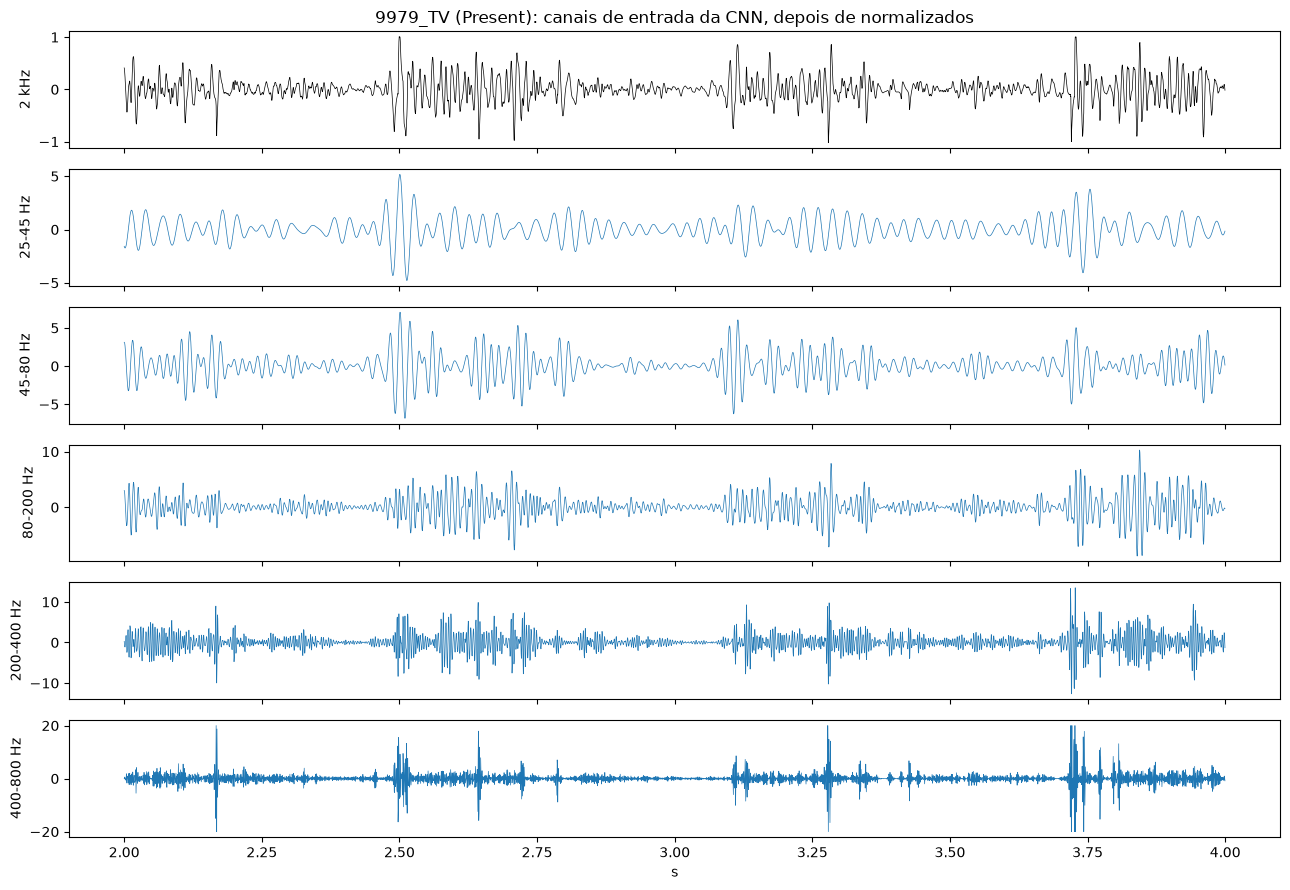

In [20]:
name = "9979_TV"
r = dev_recs.set_index("recording").loc[name]
x2k = downsample(load_wav(r["wav"]))
z = robust_normalize(filterbank(x2k))
t = np.arange(len(x2k)) / SR
sel = (t >= 2) & (t < 4)

fig, axes = plt.subplots(len(BANDS) + 1, 1, figsize=(13, 9), sharex=True)
axes[0].plot(t[sel], x2k[sel], lw=0.5, color="black"); axes[0].set_ylabel("2 kHz")
for i, (lo, hi) in enumerate(BANDS):
    axes[i + 1].plot(t[sel], z[sel, i], lw=0.5)
    axes[i + 1].set_ylabel(f"{lo}-{hi} Hz")
axes[-1].set_xlabel("s"); axes[0].set_title(f"{name} ({r['rec_label']}): canais de entrada da CNN, depois de normalizados")
plt.tight_layout(); plt.show()

In [21]:
clipped = []
for path in dev_recs.sample(300, random_state=SEED)["wav"]:
    zz = robust_normalize(filterbank(downsample(load_wav(path))))
    clipped.append((np.abs(zz) >= CLIP).mean(axis=0))
print("fração de amostras cortadas por banda:", {f"{lo}-{hi} Hz": round(float(v), 4)
                                                 for (lo, hi), v in zip(BANDS, np.mean(clipped, axis=0))})
w = sliding_windows(z, WIN, HOP)
print(f"{name}: {len(x2k) / SR:.1f} s -> {len(w)} janelas de {WIN_SECONDS:.0f} s (50% de sobreposição), shape {w.shape}")

fração de amostras cortadas por banda: {'25-45 Hz': 0.0005, '45-80 Hz': 0.0027, '80-200 Hz': 0.008, '200-400 Hz': 0.0122, '400-800 Hz': 0.0123}
9979_TV: 22.9 s -> 11 janelas de 4 s (50% de sobreposição), shape (11, 8000, 5)


O corte apanha bem menos de 2% das amostras, sobretudo nas bandas de cima. E não são só picos de fricção: os picos mais
altos do S1 e do S2 também ficam achatados, o que diminui os sons cardíacos em relação ao sopro. Parece inofensivo,
talvez até ajude, mas ainda não testámos. Fica por fazer uma ablação com e sem corte.

### 3.6 Entrada da RNN: frames log-mel e estados do ciclo

O sinal a 2 kHz passa a um espectrograma mel (janela de 50 ms, hop de 20 ms, 32 bandas mel entre 25 e 800 Hz). Como a
janela só tem 100 amostras, fazemos zero-padding até 256 pontos na FFT para não haver filtros mel vazios nas bandas
baixas. Depois tiramos o logaritmo e normalizamos cada banda ao longo do tempo, o que tira o efeito do ganho do
estetoscópio e do paciente.

Para cada frame guardamos também o estado no centro dela, segundo o .tsv. Estes estados são os alvos da saída
auxiliar e não entram na rede como input. No treino usamos crops de 5 s (250 frames) e na inferência janelas de 5 s
com 50% de sobreposição. Tal como na CNN, guardamos tudo em cache/rnn/.

In [22]:
MEL_HOP = int(MEL_HOP_SECONDS * SR)
MEL_WIN = int(MEL_WIN_SECONDS * SR)
N_FFT = 256


def logmel(x):
    mel = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=N_FFT, win_length=MEL_WIN, hop_length=MEL_HOP,
                                         n_mels=N_MELS, fmin=MEL_FMIN, fmax=MEL_FMAX)
    z = np.log(mel + 1e-8).T
    return ((z - z.mean(axis=0)) / (z.std(axis=0) + 1e-6)).astype(np.float32)


def frame_labels(tsv_path, n_frames):
    """Estado do .tsv (0 a 4) no centro de cada frame. O librosa centra a frame i em i * hop. As frames que caem
    fora das zonas anotadas ficam com 0."""
    seg = read_tsv(tsv_path)
    t = np.arange(n_frames) * MEL_HOP_SECONDS
    idx = np.searchsorted(seg[:, 0], t, side="right") - 1
    inside = (idx >= 0) & (t < seg[np.clip(idx, 0, None), 1])
    return np.where(inside, seg[np.clip(idx, 0, None), 2], 0).astype(np.int32)


def load_rnn_inputs(recordings, cache=True):
    """Para cada gravação calcula o log-mel e os estados por frame, e guarda tudo em cache/rnn/."""
    out = {}
    cache_dir = CACHE_DIR / "rnn"
    cache_dir.mkdir(parents=True, exist_ok=True)
    for name, wav, tsv in zip(recordings["recording"], recordings["wav"], recordings["tsv"]):
        f = cache_dir / f"{name}.npz"
        if cache and f.exists():
            d = np.load(f)
            out[name] = (d["x"], d["s"])
            continue
        x = logmel(downsample(load_wav(wav)))
        s = frame_labels(tsv, len(x))
        out[name] = (x.astype(np.float16), s.astype(np.int8))
        if cache:
            np.savez(f, x=out[name][0], s=out[name][1])
    return out

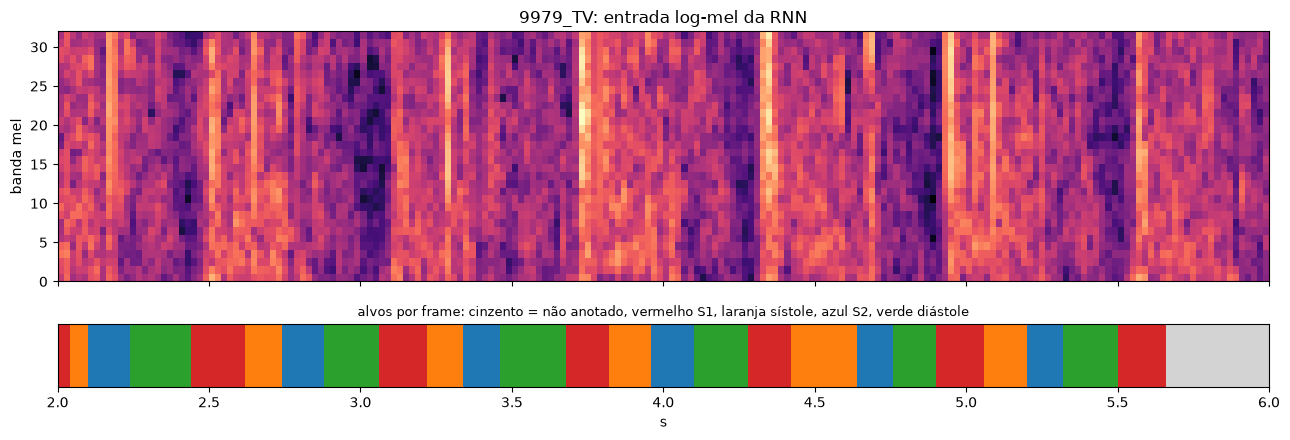

In [23]:
mel = logmel(x2k)
states = frame_labels(r["tsv"], len(mel))
tf_ = np.arange(len(mel)) * MEL_HOP_SECONDS
sel = (tf_ >= 2) & (tf_ < 6)
STATE_CMAP = plt.matplotlib.colors.ListedColormap(["lightgray", "tab:red", "tab:orange", "tab:blue", "tab:green"])

fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
axes[0].imshow(mel[sel].T, origin="lower", aspect="auto", cmap="magma", extent=[2, 6, 0, N_MELS])
axes[0].set_ylabel("banda mel"); axes[0].set_title(f"{name}: entrada log-mel da RNN")
axes[1].imshow(states[sel][None, :], aspect="auto", cmap=STATE_CMAP, vmin=0, vmax=4, extent=[2, 6, 0, 1])
axes[1].set_yticks([]); axes[1].set_xlabel("s")
axes[1].set_title("alvos por frame: cinzento = não anotado, vermelho S1, laranja sístole, azul S2, verde diástole", fontsize=9)
plt.tight_layout(); plt.show()

In [24]:
rnn = load_rnn_inputs(dev_recs)
dist = {}
for lab_ in CLASSES:
    s = np.concatenate([rnn[n][1] for n in dev_recs.loc[dev_recs["rec_label"] == lab_, "recording"]])
    dist[lab_] = np.bincount(s, minlength=len(STATES)) / len(s)
pd.DataFrame(dist, index=STATES).T.round(3)

,não anotado,S1,sístole,S2,diástole
Present,0.421,0.120,0.125,0.103,0.230
Unknown,0.720,0.057,0.065,0.049,0.109
Absent,0.468,0.108,0.122,0.095,0.207


Ao nível das frames vê-se o mesmo que na secção 3.1: a maioria das frames das gravações Unknown está no estado 0. A
saída auxiliar aprende então duas coisas que a saída do sopro pode aproveitar: onde está a sístole e se o sinal se
consegue segmentar ou não.

## 4. Modelos

### 4.1 CNN 1D

A entrada são 4 s em 5 bandas (8000 x 5). A seguir vêm cinco blocos de Conv1D (kernel 9, sem bias), BatchNorm, ReLU e
MaxPool, com 16, 32, 64, 128 e 128 feature maps e pooling de 4, 4, 4, 2 e 2. No fim há um global average pooling (o
sopro repete-se em todos os batimentos, por isso faz sentido fazer a média no tempo), dropout de 0.5 e um softmax com
3 saídas. Escolhemos os poolings de forma a que o receptive field da última conv cubra mais ou menos um ciclo
cardíaco.

In [25]:
CNN_BLOCKS = ((16, 4), (32, 4), (64, 4), (128, 2), (128, 2))
CNN_KERNEL = 9


def build_cnn1d(win=WIN, n_channels=len(BANDS), blocks=CNN_BLOCKS, kernel=CNN_KERNEL, dropout=0.5, n_classes=3):
    inp = keras.Input(shape=(win, n_channels), name="waveform")
    x = inp
    for filters, pool in blocks:
        x = layers.Conv1D(filters, kernel, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(pool)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax", name="murmur")(x)
    return keras.Model(inp, out, name="cnn1d")


def receptive_field(blocks=CNN_BLOCKS, kernel=CNN_KERNEL):
    """Receptive field (em amostras) da última conv da build_cnn1d: cada conv soma (kernel - 1) passos e cada
    pooling multiplica o tamanho do passo."""
    rf, jump = 1, 1
    for i, (_, pool) in enumerate(blocks):
        rf += (kernel - 1) * jump
        if i < len(blocks) - 1:
            rf += (pool - 1) * jump
            jump *= pool
    return rf

In [26]:
build_cnn1d().summary()
rf = receptive_field()
print(f"receptive field da última conv: {rf} amostras = {rf / SR:.2f} s "
      f"(ciclo cardíaco mediano no desenvolvimento: {dev_recs['cycle_s'].median():.2f} s)")

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ waveform (InputLayer)           │ (None, 8000, 5)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 8000, 16)       │           720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8000, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2000, 32)       │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2000, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 2000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 500, 64)        │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 125, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 125, 128)       │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 125, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 125, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 62, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 62, 128)        │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 62, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 62, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 31, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │             

 Total params: 246,803 (964.07 KB)

 Trainable params: 246,067 (961.20 KB)

 Non-trainable params: 736 (2.88 KB)

receptive field da última conv: 1832 amostras = 0.92 s (ciclo cardíaco mediano no desenvolvimento: 0.58 s)


### 4.2 BiGRU multitarefa

| O que vimos na secção 3 | Escolha |
|---|---|
| Os sopros são quase sempre sistólicos e só se destacam dentro da sístole | A rede deve saber onde está a sístole, por isso uma saída auxiliar prevê o estado de cada frame |
| A maioria das gravações Unknown não se consegue segmentar (estado 0 do .tsv) | "Não anotado" é uma das classes auxiliares, para a rede aprender um sinal de qualidade por frame |
| O sopro só aparece numa parte das frames | Attention pooling: a gravação é representada por uma média das frames com pesos aprendidos |
| ~2000 gravações de treino por fold | GRU em vez de LSTM (menos parâmetros), 64 unidades por direção, 2 camadas |

```
log-mel (T x 32) -> BiGRU(64) -> BiGRU(64) -+-> Dense(5, softmax) em cada frame ----------> "seg"     (auxiliar, alvos do .tsv)
                                            |
                                            +-> attention pooling -> Dense(32) -> Dense(3) -> "murmur"
```

A loss é $CE_{murmur} + \lambda \, CE_{seg}$, com $\lambda = 0.5$ por agora. Na inferência só usamos a saída "murmur",
por isso o modelo também funciona em gravações sem ficheiro de segmentação, como a secção 1.1 obriga.

In [27]:
def build_bigru_mt(n_mels=N_MELS, units=64, n_layers=2, dropout=0.3, n_states=len(STATES), n_classes=3):
    """A "seg" prevê o estado de cada frame. Para a "murmur", uma Dense dá uma pontuação a cada frame, o softmax
    transforma-as em pesos (attention) e fazemos a média pesada das frames."""
    inp = keras.Input(shape=(None, n_mels), name="logmel")
    x = inp
    for _ in range(n_layers):
        x = layers.Bidirectional(layers.GRU(units, return_sequences=True, dropout=0.1))(x)
    seg = layers.Dense(n_states, activation="softmax", name="seg")(x)

    att = layers.Dense(1)(x)
    att = layers.Softmax(axis=1, name="attention")(att)
    pooled = layers.Flatten()(layers.Dot(axes=1)([att, x]))
    h = layers.Dropout(dropout)(pooled)
    h = layers.Dense(32, activation="relu")(h)
    murmur = layers.Dense(n_classes, activation="softmax", name="murmur")(h)
    return keras.Model(inp, {"murmur": murmur, "seg": seg}, name="bigru_mt")

In [28]:
build_bigru_mt().summary()

Model: "bigru_mt"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ logmel (InputLayer) │ (None, None, 32)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, None, 128) │     37,632 │ logmel[0][0]      │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, None, 128) │     74,496 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 1)   │        129 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention (Softmax) │ (None, None, 1)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1, 128)    │          0 │ attention[0][0],  │
│                     │                   │            │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 128)       │          0 │ dot[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      4,128 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ murmur (Dense)      │ (None, 3)         │         99 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seg (Dense)         │ (None, None, 5)   │        645 │ bidirectional_1[… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 117,129 (457.54 KB)

 Trainable params: 117,129 (457.54 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Estratégia de treino

Usamos o Adam com learning rate 1e-3 (o valor por defeito, que foi o que melhor funcionou nas aulas) e mini-batches
de 32 crops. Uma época corresponde a um crop aleatório de cada gravação de treino.

Como data augmentation, além da posição aleatória do crop, mudamos o ganho ao acaso (entre 0.8 e 1.25) e invertemos a
polaridade. Não invertemos no tempo porque isso trocava o S1 com o S2. Para regularizar temos ainda batch
normalization, dropout de 0.5 e early stopping.

O early stopping é feito sobre a própria métrica. No fim de cada época calculamos a WA por paciente no fold de
validação, com as regras da secção 1.3, e o treino acaba ao fim de 10 épocas sem melhorias (no máximo 60), voltando
aos melhores pesos. Não usámos a val_loss porque é calculada por crop e não reflete a decisão por paciente.

Para o desequilíbrio das classes comparámos duas configurações:

| | loss | agregação por paciente | regra de decisão |
|---|---|---|---|
| E1 | cross-entropy com class weights (inverso da frequência) | média das gravações | argmax |
| E2 | cross-entropy sem pesos | máximo das gravações para Present, média para as outras | regra de Bayes para a WA |

A E1 é a abordagem mais habitual. A E2 segue as regras da secção 1.3, e de propósito não põe pesos na loss: os custos
da métrica já entram na decisão e não os queremos contar duas vezes.

O código genérico do treino está em `src/training.py`: o dataset que tira os crops aleatórios, a inferência com
janelas deslizantes, o callback que calcula a WA no fim de cada época e o ciclo de CV. Não está aqui porque é só
maquinaria do Keras. A métrica e as regras de decisão que ele usa são as da secção 1, e passamos-lhas como argumento
através da função wa_score.

## 5. Treino e validação

### 5.1 Cross-validation da CNN

Cada configuração é treinada nos 5 folds do conjunto de desenvolvimento. Cada paciente de validação é previsto pelo
modelo do fold em que ficou de fora, por isso no fim cada paciente tem exatamente uma previsão out-of-fold. Com
`RETRAIN_CNN = False` carregamos as previsões guardadas em results/.

In [29]:
def wa_score(aggregation, decision):
    """Função que o run_cv usa no early stopping: agrega as gravações por paciente, decide e calcula a WA."""
    def score(rec_probs):
        pp = predict_patients(rec_probs, aggregation, decision)
        return weighted_accuracy(labels.loc[pp.index], pp["pred"])
    return score


VARIANTS = {
    "cnn_E1": dict(class_weighted=True,  aggregation="mean",        decision="argmax"),
    "cnn_E2": dict(class_weighted=False, aggregation="max_present", decision="bayes"),
}
OOF, HIST = {}, {}
cnn_arrays = None
for name, v in VARIANTS.items():
    oof_path = RESULTS_DIR / f"{name}_oof.csv"
    hist_path = RESULTS_DIR / f"{name}_histories.json"
    if RETRAIN_CNN or not (oof_path.exists() and hist_path.exists()):
        if cnn_arrays is None:
            cnn_arrays = load_cnn_inputs(dev_recs)
        oof, hist = run_cv(build_cnn1d, cnn_arrays, dev_recs, splits, name, WIN, CLASSES,
                           wa_score(v["aggregation"], v["decision"]), class_weighted=v["class_weighted"],
                           epochs=60, patience=10, seed=SEED, models_dir=MODELS_DIR)
        oof.to_csv(oof_path, index=False)
        hist_path.write_text(json.dumps({k: {m: [float(x) for x in vals] for m, vals in h.items()}
                                         for k, h in hist.items()}))
    else:
        print(f"{name}: a carregar as previsões out-of-fold guardadas ({oof_path.name})")
    OOF[name] = pd.read_csv(oof_path)
    HIST[name] = {int(k): h for k, h in json.loads(hist_path.read_text()).items()}

cnn_E1: a carregar as previsões out-of-fold guardadas (cnn_E1_oof.csv)
cnn_E2: a carregar as previsões out-of-fold guardadas (cnn_E2_oof.csv)


### 5.2 Curvas de aprendizagem

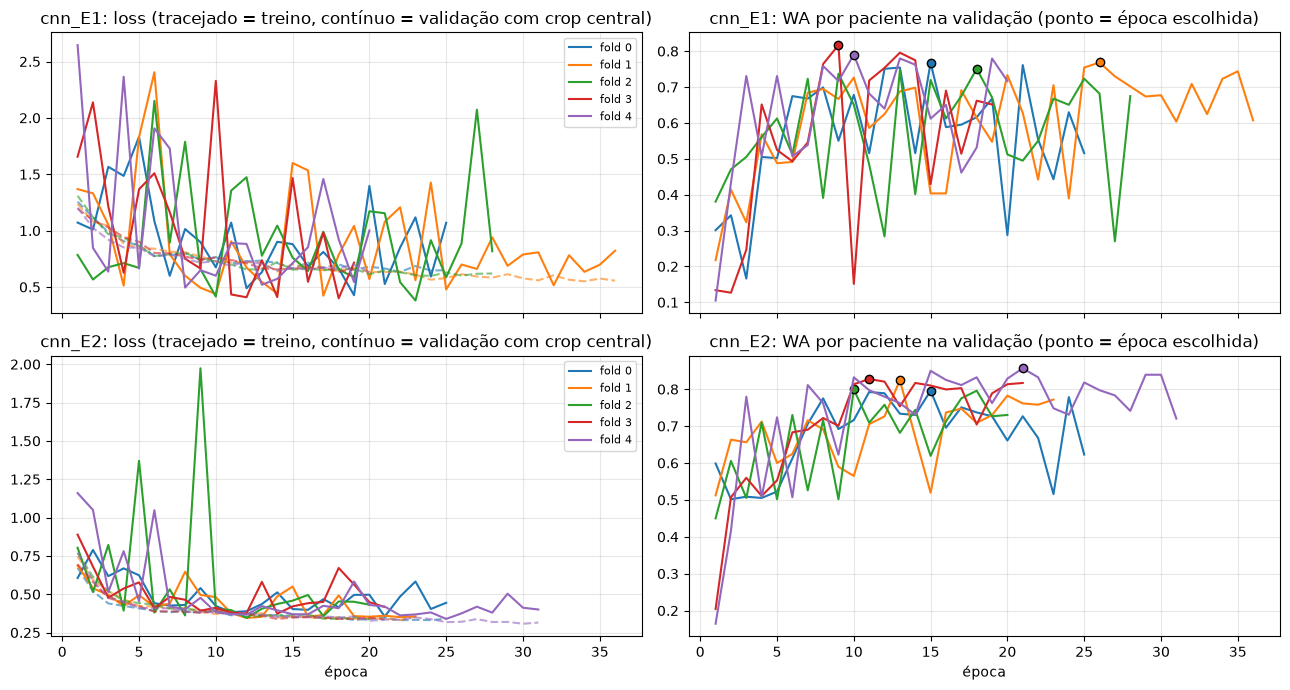

,cnn_E1,cnn_E2
fold 0,melhor época 15 de 25,melhor época 15 de 25
fold 1,melhor época 26 de 36,melhor época 13 de 23
fold 2,melhor época 18 de 28,melhor época 10 de 20
fold 3,melhor época 9 de 19,melhor época 11 de 21
fold 4,melhor época 10 de 20,melhor época 21 de 31


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for row, name in enumerate(VARIANTS):
    for k, h in HIST[name].items():
        ep = np.arange(1, len(h["loss"]) + 1)
        axes[row, 0].plot(ep, h["loss"], "--", color=f"C{k}", alpha=0.6)
        axes[row, 0].plot(ep, h["val_loss"], "-", color=f"C{k}", label=f"fold {k}")
        wa = np.array(h["val_patient_wa"])
        axes[row, 1].plot(ep, wa, "-", color=f"C{k}")
        axes[row, 1].plot(np.argmax(wa) + 1, wa.max(), "o", color=f"C{k}", markeredgecolor="black")
    axes[row, 0].set_title(f"{name}: loss (tracejado = treino, contínuo = validação com crop central)")
    axes[row, 1].set_title(f"{name}: WA por paciente na validação (ponto = época escolhida)")
    axes[row, 0].legend(fontsize=8)
for ax in axes.flat:
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("época")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "cnn_learning_curves.png", dpi=120); plt.show()

pd.DataFrame({name: {f"fold {k}": f"melhor época {int(np.argmax(h['val_patient_wa'])) + 1} de {len(h['loss'])}"
                     for k, h in HIST[name].items()} for name in VARIANTS})

As curvas da E1 são muito mais ruidosas do que as da E2: a WA de validação chega a saltar 0.6 de uma época para a
outra. Voltamos a isto na secção 6.5.

### 5.3 Smoke run da RNN: fold 0, 10 épocas

A RNN ainda não foi avaliada com CV. Por agora fizemos um smoke run curto, só no fold 0, para confirmar que o pipeline
funciona. Não é um resultado para comparar com a CNN. Tratamos o desequilíbrio como na E2 (cross-entropy sem pesos,
máximo para Present e regra de Bayes). Crops de 5 s, Adam com learning rate 1e-3, batch de 32 e early stopping na WA
por paciente da validação. Ainda sem data augmentation.

In [31]:
RNN_VARIANT = dict(aggregation="max_present", decision="bayes")
rnn_oof_path = RESULTS_DIR / "rnn_smoke_oof.csv"
rnn_hist_path = RESULTS_DIR / "rnn_smoke_history.json"
rnn_model_path = MODELS_DIR / "rnn_smoke_fold0.keras"
if RETRAIN_RNN or not (rnn_oof_path.exists() and rnn_hist_path.exists() and rnn_model_path.exists()):
    rnn_oof, hist = run_cv(build_bigru_mt, rnn, dev_recs, splits, "rnn_smoke", RNN_WIN, CLASSES,
                           wa_score(RNN_VARIANT["aggregation"], RNN_VARIANT["decision"]), folds=[0],
                           epochs=10, patience=10, multitask=True, loss_weights={"murmur": 1.0, "seg": 0.5},
                           seed=SEED, models_dir=MODELS_DIR)
    rnn_oof.to_csv(rnn_oof_path, index=False)
    rnn_hist_path.write_text(json.dumps({m: [float(x) for x in vals] for m, vals in hist[0].items()}))
else:
    print("a carregar o smoke run guardado")
rnn_oof = pd.read_csv(rnn_oof_path)
h = json.loads(rnn_hist_path.read_text())

a carregar o smoke run guardado


melhor época (restaurada): 6 de 10


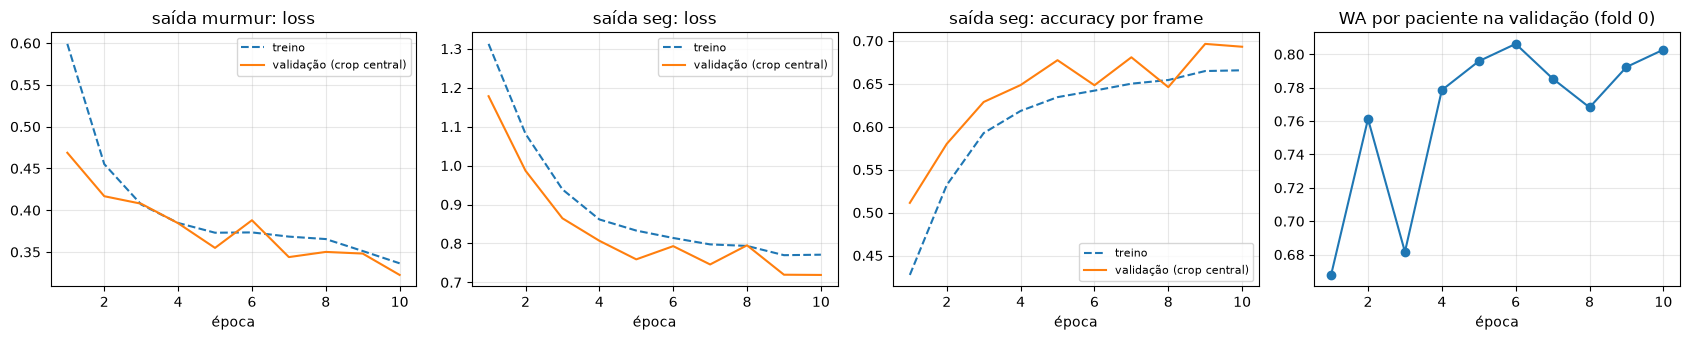

accuracy por frame a prever sempre o estado mais frequente: 0.473


In [32]:
ep = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, key, title in [(axes[0], "murmur_loss", "saída murmur: loss"), (axes[1], "seg_loss", "saída seg: loss"),
                       (axes[2], "seg_accuracy", "saída seg: accuracy por frame")]:
    ax.plot(ep, h[key], "--", label="treino"); ax.plot(ep, h[f"val_{key}"], "-", label="validação (crop central)")
    ax.set_title(title); ax.legend(fontsize=8)
axes[3].plot(ep, h["val_patient_wa"], "o-"); axes[3].set_title("WA por paciente na validação (fold 0)")
print(f"melhor época (restaurada): {int(np.argmax(h['val_patient_wa'])) + 1} de {len(h['loss'])}")
for ax in axes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "rnn_smoke_curves.png", dpi=120); plt.show()

all_states = np.concatenate([rnn[n][1] for n in dev_recs["recording"]])
print(f"accuracy por frame a prever sempre o estado mais frequente: {np.bincount(all_states).max() / len(all_states):.3f}")

Para ver se a saída auxiliar aprende mesmo o ciclo cardíaco, comparamos os estados previstos com os anotados numa
gravação de validação, com o modelo na melhor época.

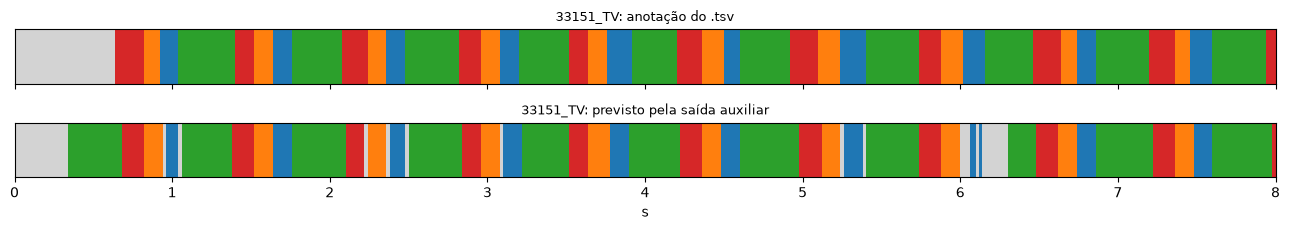

concordância por frame na gravação inteira: 0.847


In [33]:
rnn_model = keras.models.load_model(rnn_model_path)
_, va = fold_data(dev_recs, splits, 0)
name = va.loc[va["rec_label"] == "Present", "recording"].iloc[0]
x, s = rnn[name]
pred_states = rnn_model.predict(x[None].astype(np.float32), verbose=0)["seg"][0].argmax(axis=-1)

n = min(len(s), 400)
fig, axes = plt.subplots(2, 1, figsize=(13, 2.4), sharex=True)
for ax, st, title in [(axes[0], s, "anotação do .tsv"), (axes[1], pred_states, "previsto pela saída auxiliar")]:
    ax.imshow(st[None, :n], aspect="auto", cmap=STATE_CMAP, vmin=0, vmax=4, extent=[0, n * MEL_HOP_SECONDS, 0, 1])
    ax.set_yticks([]); ax.set_title(f"{name}: {title}", fontsize=9)
axes[1].set_xlabel("s"); plt.tight_layout(); plt.show()
print(f"concordância por frame na gravação inteira: {(pred_states == s).mean():.3f}")

### 5.4 E o conjunto de teste?

Ainda não lhe tocámos. Só o vamos usar uma vez, no fim do projeto, depois de as configurações finais estarem
escolhidas com a CV. Nessa altura juntamos, para cada arquitetura, os cinco modelos dos folds num ensemble (cada um
parou numa época escolhida no seu fold de validação) e avaliamos esse ensemble nos 189 pacientes de teste. É esse o
número que vai para os slides como estimativa sem viés.

## 6. Avaliação e métricas

### 6.1 Resultados por paciente (out-of-fold)

Reportamos a WA de cada fold (média ± desvio padrão) e a matriz de confusão com os cinco folds juntos (linhas =
previsto, colunas = verdadeiro).

In [34]:
def evaluate(oof, aggregation, decision):
    """Devolve a WA de cada fold e as previsões por paciente com os folds todos juntos."""
    per_fold = []
    for k, g in oof.groupby("fold"):
        pp = predict_patients(g, aggregation, decision)
        per_fold.append(weighted_accuracy(labels.loc[pp.index], pp["pred"]))
    return np.array(per_fold), predict_patients(oof, aggregation, decision)


dev_labels = splits.loc[splits["split"] == "dev", "murmur"]
rows, pooled = [], {}
for name, v in VARIANTS.items():
    per_fold, pp = evaluate(OOF[name], v["aggregation"], v["decision"])
    pooled[name] = pp
    rows.append(dict(model=name, **{f"fold {k}": wa for k, wa in enumerate(per_fold)},
                     WA_mean=per_fold.mean(), WA_std=per_fold.std(ddof=1)))
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(RESULTS_DIR / "cnn_cv_summary.csv")

print("referência nos mesmos pacientes: sempre Present WA = %.3f | sempre Absent WA = %.3f" % (
      weighted_accuracy(dev_labels, ["Present"] * len(dev_labels)),
      weighted_accuracy(dev_labels, ["Absent"] * len(dev_labels))))
summary.round(3)

referência nos mesmos pacientes: sempre Present WA = 0.499 | sempre Absent WA = 0.388


,fold 0,fold 1,fold 2,fold 3,fold 4,WA_mean,WA_std
model,,,,,,,
cnn_E1,0.768,0.768,0.751,0.817,0.790,0.779,0.025
cnn_E2,0.796,0.825,0.799,0.827,0.857,0.821,0.025


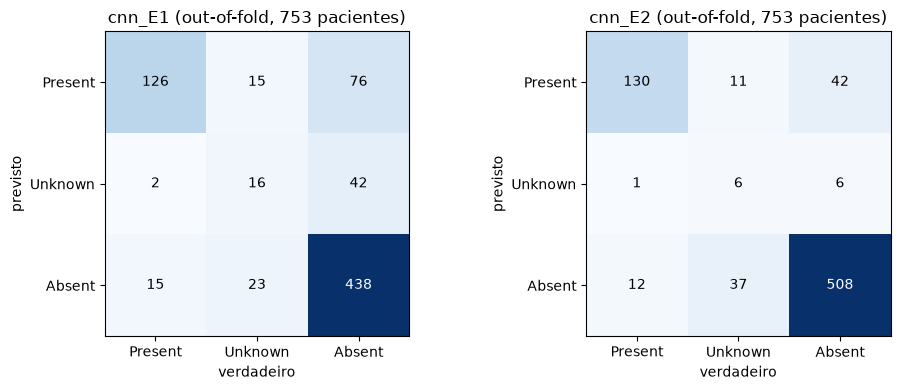

Métricas adicionais (out-of-fold, folds todos juntos):


,WA,recall_Present,recall_Unknown,recall_Absent,macro_F1
model,,,,,
cnn_E1,0.779,0.881,0.296,0.788,0.61
cnn_E2,0.821,0.909,0.111,0.914,0.63


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
extra = []
for ax, (name, pp) in zip(axes, pooled.items()):
    plot_confusion(confusion_matrix_pua(labels.loc[pp.index], pp["pred"]),
                   f"{name} (out-of-fold, {len(pp)} pacientes)", ax)
    extra.append(dict(model=name, **report(labels.loc[pp.index], pp["pred"])))
plt.tight_layout(); plt.savefig(FIGURES_DIR / "cnn_confusion_matrices.png", dpi=120); plt.show()
print("Métricas adicionais (out-of-fold, folds todos juntos):")
pd.DataFrame(extra).set_index("model").round(3)

### 6.2 O que é que faz a diferença?

Como guardámos as probabilidades out-of-fold de cada gravação, dá para testar todas as combinações de agregação e
regra de decisão sem voltar a treinar. Assim conseguimos separar o efeito da loss do efeito da decisão. Há um
pormenor: a época de early stopping de cada modelo foi escolhida com a sua própria regra, por isso as outras
combinações ficam um pouco prejudicadas.

In [36]:
rows = []
for name in VARIANTS:
    for aggregation in ["mean", "max_present"]:
        for decision in ["argmax", "bayes"]:
            per_fold, pp = evaluate(OOF[name], aggregation, decision)
            r_ = report(labels.loc[pp.index], pp["pred"])
            rows.append(dict(training=name, aggregation=aggregation, decision=decision,
                             WA_mean=per_fold.mean(), WA_std=per_fold.std(ddof=1),
                             recall_P=r_["recall_Present"], recall_U=r_["recall_Unknown"], recall_A=r_["recall_Absent"]))
posthoc = pd.DataFrame(rows)
posthoc.to_csv(RESULTS_DIR / "cnn_posthoc_rules.csv", index=False)
posthoc.round(3)

,training,aggregation,decision,WA_mean,WA_std,recall_P,recall_U,recall_A
0,cnn_E1,mean,argmax,0.779,0.025,0.881,0.296,0.788
1,cnn_E1,mean,bayes,0.569,0.059,0.993,0.241,0.121
2,cnn_E1,max_present,argmax,0.765,0.027,0.937,0.278,0.685
3,cnn_E1,max_present,bayes,0.543,0.040,0.993,0.222,0.058
4,cnn_E2,mean,argmax,0.667,0.035,0.559,0.000,0.998
5,cnn_E2,mean,bayes,0.776,0.041,0.783,0.111,0.959
6,cnn_E2,max_present,argmax,0.693,0.050,0.615,0.000,0.995
7,cnn_E2,max_present,bayes,0.821,0.025,0.909,0.111,0.914


### 6.3 Ao nível da gravação: onde é que o modelo falha?

Recall por gravação (argmax das probabilidades da gravação), separado pelo rótulo da gravação e pelo local de
auscultação.

In [37]:
for name in VARIANTS:
    oof = OOF[name]
    pred = np.array(CLASSES)[oof[PROB_COLS].to_numpy().argmax(axis=1)]
    print(name)
    display(oof.assign(correct=pred == oof["rec_label"])
               .groupby(["rec_label", "location"])["correct"].mean().unstack().round(2))

cnn_E1


location,AV,MV,PV,Phc,TV
rec_label,,,,,
Absent,0.64,0.70,0.79,0.5,0.79
Present,0.93,0.94,0.91,1.0,0.91
Unknown,0.46,0.32,0.27,NaN,0.18


cnn_E2


location,AV,MV,PV,Phc,TV
rec_label,,,,,
Absent,0.99,0.99,0.99,1.0,1.00
Present,0.62,0.56,0.68,1.0,0.63
Unknown,0.00,0.00,0.00,NaN,0.00


### 6.4 A RNN no fold 0

Para ter uma primeira ideia, comparamos o smoke run da RNN com a CNN E2 no mesmo fold.

In [38]:
pp = predict_patients(rnn_oof, RNN_VARIANT["aggregation"], RNN_VARIANT["decision"])
cnn_fold0 = evaluate(OOF["cnn_E2"][OOF["cnn_E2"]["fold"] == 0], "max_present", "bayes")[0][0]
print(f"só o fold 0, 10 épocas, sem afinação: WA por paciente da RNN = {weighted_accuracy(labels.loc[pp.index], pp['pred']):.3f}"
      f" (CNN E2 no mesmo fold: {cnn_fold0:.3f})")
confusion_matrix_pua(labels.loc[pp.index], pp["pred"])

só o fold 0, 10 épocas, sem afinação: WA por paciente da RNN = 0.806 (CNN E2 no mesmo fold: 0.796)


array([[ 26,   1,   8],
       [  0,   0,   0],
       [  3,  10, 103]])

### 6.5 Interpretação

1. As duas configurações da CNN ficam bem acima da referência, e a E2 ganha à E1 em todos os folds: WA de
   0.821 ± 0.025 contra 0.779 ± 0.025 (prever sempre Present dá 0.499).

2. O que mais pesa é a regra de decisão (tabela da secção 6.2). O mesmo modelo E2 com argmax fica só em 0.693: falha
   38% dos pacientes Present e nunca prevê Unknown. Com a regra de Bayes sobe para 0.821. Usar o máximo sobre os
   locais em vez da média dá mais cerca de 0.045 (de 0.776 para 0.821), como a secção 2.4 fazia prever.

3. Juntar class weights com a regra de Bayes corre mal. Com o E1 e a regra de Bayes o WA cai para 0.54-0.57, porque o
   modelo passa a dizer Present para quase toda a gente (o recall de Absent fica entre 6 e 12%). Faz sentido, porque
   os pesos já estavam na loss e estamos a aplicá-los outra vez na decisão.

4. Os class weights deixam o treino instável (secção 5.2). Com pesos pelo inverso da frequência, uma gravação Unknown
   pesa ~16 vezes mais do que uma Absent, e as curvas de validação da E1 saltam muito mais do que as da E2. Com uma
   curva tão ruidosa, o early stopping também pode calhar numa época com sorte.

5. O ponto fraco é o Unknown. Na matriz da E2 só 6 dos 54 pacientes Unknown são reconhecidos (37 vão para Absent), e
   ao nível da gravação a E2 nunca escolhe Unknown pelo argmax. O Present é bem detetado (130 de 143) e há 42 falsos
   alarmes em 556 pacientes Absent.

6. A RNN também já funciona: WA de 0.806 no fold 0 depois de 10 épocas sem afinação, contra 0.796 da CNN E2 no mesmo
   fold. A saída auxiliar aprende o ciclo (a accuracy por frame passa de 0.51 para 0.69, contra 0.47 de prever sempre
   o estado mais frequente) e as curvas ainda estão a melhorar na época 10. Como é só um fold não dá para comparar os
   modelos, e o Unknown continua por resolver (0 de 11 no fold 0).

7. Estes números são otimistas. A época é escolhida no mesmo fold de validação em que medimos a WA, e como as curvas
   são ruidosas a média da CV fica acima do valor real (sobretudo na E1). A estimativa sem viés vai ser a do ensemble
   dos folds no conjunto de teste (secção 5.4). Ter valores perto dos melhores do Challenge (~0.78 no teste escondido
   deles) não quer dizer que estejamos ao nível deles.

## 7. Consequências práticas

A WA resume tudo num número, mas não diz o que acontece a uma criança concreta. Imaginemos que o modelo é usado num
rastreio e que cada previsão leva a uma ação diferente: Present quer dizer que a criança vai ao cardiologista,
Unknown que se repete a auscultação, e Absent que não se faz mais nada. Pegando nas matrizes de confusão da secção
6.1, vemos o que acontece em cada 100 crianças com a mesma mistura de classes do nosso conjunto de desenvolvimento.

In [39]:
ACTIONS = {"Present": "vai ao cardiologista", "Unknown": "repete a auscultação", "Absent": "não faz mais nada"}
GROUPS = {"Present": "tem sopro", "Unknown": "gravação inconclusiva", "Absent": "não tem sopro"}


def per_100(m):
    """Passa a matriz de confusão para 100 crianças. Cada linha é um tipo de criança (a classe verdadeira) e cada
    coluna o que lhe acontece (a classe prevista)."""
    return pd.DataFrame((100 * m / m.sum()).T, index=[GROUPS[c] for c in CLASSES],
                        columns=[ACTIONS[c] for c in CLASSES])


practical = []
for name, pp in pooled.items():
    m = confusion_matrix_pua(labels.loc[pp.index], pp["pred"])
    n = m.sum(axis=0)
    print(f"{name}: o que acontece em cada 100 crianças rastreadas")
    display(per_100(m).round(1))
    practical.append({"modelo": name,
                      "sopros dados como saudáveis (%)": 100 * m[2, 0] / n[0],
                      "saudáveis enviados ao cardiologista (%)": 100 * m[0, 2] / n[2],
                      "inconclusivas dadas como saudáveis (%)": 100 * m[2, 1] / n[1],
                      "idas ao cardiologista por 100 crianças": 100 * m[0].sum() / m.sum(),
                      "repetições por 100 crianças": 100 * m[1].sum() / m.sum()})
pd.DataFrame(practical).set_index("modelo").round(1)

cnn_E1: o que acontece em cada 100 crianças rastreadas


,vai ao cardiologista,repete a auscultação,não faz mais nada
tem sopro,16.7,0.3,2.0
gravação inconclusiva,2.0,2.1,3.1
não tem sopro,10.1,5.6,58.2


cnn_E2: o que acontece em cada 100 crianças rastreadas


,vai ao cardiologista,repete a auscultação,não faz mais nada
tem sopro,17.3,0.1,1.6
gravação inconclusiva,1.5,0.8,4.9
não tem sopro,5.6,0.8,67.5


,sopros dados como saudáveis (%),saudáveis enviados ao cardiologista (%),inconclusivas dadas como saudáveis (%),idas ao cardiologista por 100 crianças,repetições por 100 crianças
modelo,,,,,
cnn_E1,10.5,13.7,42.6,28.8,8.0
cnn_E2,8.4,7.6,68.5,24.3,1.7


Com a E2, em cada 100 crianças rastreadas cerca de 24 são enviadas ao cardiologista. Dessas, 17 têm mesmo um
sopro, 1.5 tinham uma gravação inconclusiva e 5.6 são crianças sem sopro, ou seja, falsos alarmes. Do outro lado,
1.6 em cada 100 crianças têm um sopro e vão para casa sem mais nada: são 12 dos 143 pacientes Present do
desenvolvimento (8.4%). Os falsos alarmes são 42 dos 556 pacientes Absent (7.6%). Para um rastreio esta troca parece
razoável, porque um falso alarme custa uma consulta ou um ecocardiograma a mais, e um sopro falhado pode ser uma
doença cardíaca que fica por diagnosticar.

O problema está nas gravações inconclusivas. Com a E2, 37 das 54 (68.5%) acabam em "não faz mais nada", quando o mais
sensato era repetir a auscultação. Na prática, uma gravação com muito ruído não devia levar o sistema a dizer que está
tudo bem. É aqui que a E1 se porta melhor: só deixa passar 42.6% das inconclusivas e pede para repetir 8 vezes em
cada 100 crianças, contra 1.7 na E2. Mas paga isso com mais falsos alarmes (13.7% das crianças sem sopro vão ao
cardiologista, quase o dobro da E2) e com mais sopros falhados (10.5%). Pela métrica do Challenge a E2 ganha, mas na
prática a escolha também depende do que custa repetir uma auscultação.

Daqui tiramos duas conclusões para o resto do projeto. A primeira é que a prioridade é o Unknown: precisamos de um
sinal de qualidade (a saída de segmentação da RNN é uma candidata) para as gravações más serem reconhecidas e
repetidas, em vez de passarem como Absent. A segunda é que estes números ainda são otimistas, porque vêm da CV com
early stopping no próprio fold (secção 6.5), e vêm de um único dataset, com duas campanhas de rastreio. Antes de
dizermos o que o modelo faria num rastreio a sério, precisamos pelo menos da avaliação no conjunto de teste.

## 8. Estado e próximos passos

| Etapa | CNN 1D | BiGRU multitarefa |
|---|---|---|
| Pré-processamento | feito | feito |
| Arquitetura | feito | feito |
| Estratégia de treino | feito (E1 vs E2) | em curso (só o smoke run) |
| CV de 5 folds | feito | por fazer |
| Afinação | por fazer: janela, pooling, bandas, corte | por fazer: $\lambda$ (incluindo $\lambda = 0$), unidades, augmentation |

O que falta para os dois modelos:

1. melhorar o Unknown: afinar os limiares de decisão nas previsões out-of-fold (nunca no teste) e juntar um sinal de
   qualidade;
2. na RNN, a CV completa de 5 folds e a ablação $\lambda = 0$ (sem saída auxiliar) contra $\lambda > 0$, para saber
   se os alvos de segmentação ajudam mesmo;
3. juntar os cinco modelos dos folds num ensemble, para cada arquitetura;
4. avaliar cada modelo final uma única vez no conjunto de teste;
5. escrever o script de previsão para os dados escondidos (CSV `patient_id,murmur`).